# Hibrida sederhana: berbobot dan beralih

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab02_pendekatan_dasar/04_hibrida_sederhana.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 2 · Kode 2.3.1

**Tujuan belajar**

- Memahami dua cara menggabungkan prediksi CF dan CBF.
- Melihat mengapa hibrida membantu pada item yang jarang dinilai (cold-start item).
- Menyetel κ dan τ dari data validasi, bukan dari intuisi.

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

> Eksperimen B memakai **model galat yang diasumsikan** (galat CF mengecil seiring jumlah rating). Ini ilustrasi mekanisme, bukan pengukuran.

## 1. Kode dari buku

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def hibrida_berbobot(pred_cf, pred_cbf, n_item, kappa=10.0):
    """Bobot CF naik seiring jumlah rating item (Persamaan 2-13)."""
    a = n_item / (n_item + kappa)
    return a * pred_cf + (1 - a) * pred_cbf


def hibrida_beralih(pred_cf, pred_cbf, n_item, tau=5):
    """CF bila item cukup dinilai, selain itu CBF (Persamaan 2-12)."""
    return np.where(n_item >= tau, pred_cf, pred_cbf)

In [2]:
n_item = np.array([0, 2, 10, 50])            # jumlah rating tiap item
pred_cf = np.full(4, 4.5)                    # CF dan CBF dibuat konstan
pred_cbf = np.full(4, 3.5)                   # agar efek bobot terlihat
print("n_item  :", n_item)
print("berbobot:", np.round(hibrida_berbobot(pred_cf, pred_cbf, n_item), 2))
print("beralih :", hibrida_beralih(pred_cf, pred_cbf, n_item))

n_item  : [ 0  2 10 50]
berbobot: [3.5  3.67 4.   4.33]
beralih : [3.5 3.5 4.5 4.5]


## 2. Eksperimen A: bagaimana bobot bergerak

Kurva bobot CF `a = n / (n + κ)` untuk beberapa κ. Pada n = κ bobotnya tepat 0,5.

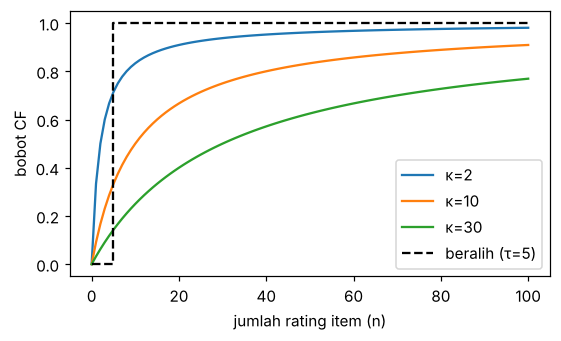

In [3]:
n = np.arange(0, 101)
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for kappa in (2, 10, 30):
    ax.plot(n, n / (n + kappa), label=f"κ={kappa}")
ax.step(n, (n >= 5).astype(float), "k--", where="post", label="beralih (τ=5)")
ax.set(xlabel="jumlah rating item (n)", ylabel="bobot CF")
ax.legend()
fig.tight_layout()

## 3. Eksperimen B: kapan hibrida menang?

Asumsi simulasi: kebenaran adalah rating sebenarnya; galat CF mengecil seiring jumlah rating item (simpangan baku ∝ 1/√(n+1)), sedangkan galat CBF tetap (simpangan baku 0,8). Kita bandingkan RMSE per kelompok popularitas item.

In [4]:
rng = np.random.default_rng(0)
N = 20000
n_rating = np.minimum(rng.zipf(1.6, N), 200)               # banyak item hanya sedikit rating
y = rng.normal(3.5, 0.8, N)
cf = y + rng.normal(0, 1.8 / np.sqrt(n_rating + 1))        # galat CF mengecil dengan n
cbf = y + rng.normal(0, 0.8, N)                            # galat CBF konstan

def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))

bins = [(0, 1), (2, 4), (5, 14), (15, 200)]
rows = []
for lo, hi in bins:
    m = (n_rating >= lo) & (n_rating <= hi)
    rows.append({"n_rating": f"{lo}-{hi}", "item_%": 100 * m.mean(),
                 "CF": rmse(cf[m], y[m]), "CBF": rmse(cbf[m], y[m]),
                 "berbobot": rmse(hibrida_berbobot(cf, cbf, n_rating)[m], y[m]),
                 "beralih": rmse(hibrida_beralih(cf, cbf, n_rating)[m], y[m])})
hasil = pd.DataFrame(rows).set_index("n_rating")
print(hasil.round(3))

# klaim yang diuji: pada kelompok jarang dinilai, hibrida berbobot lebih baik daripada CF saja
assert hasil.iloc[0]["berbobot"] < hasil.iloc[0]["CF"]

          item_%     CF    CBF  berbobot  beralih
n_rating                                         
0-1       43.635  1.288  0.803     0.743    0.803
2-4       26.680  0.957  0.797     0.665    0.797
5-14      14.905  0.628  0.803     0.521    0.628
15-200    14.780  0.293  0.778     0.273    0.293


**Interpretasi (dari asumsi simulasi).** CF sangat buruk pada item yang nyaris tak punya rating, CBF stabil tetapi tidak membaik seiring bertambahnya rating. Hibrida beralih mengikuti yang terbaik di ujung-ujung rentang, tetapi bisa lebih buruk daripada hibrida berbobot di sekitar ambang τ karena memakai CF yang masih berisik. Hibrida berbobot unggul atas keduanya di semua kelompok. Itu bergantung pada asumsi simulasi bahwa galat CF dan CBF *independen*. Pada data nyata galat keduanya sering berkorelasi, sehingga keuntungannya lebih kecil.

Ini hanya menunjukkan mekanisme. Bentuk kurva galat CF dan CBF pada data nyata harus diukur.

## 4. Eksperimen C: menyetel κ pada data validasi

In [5]:
idx = rng.permutation(N); val, tes = idx[: N // 2], idx[N // 2:]
kappas = [0.5, 1, 2, 5, 10, 20, 50]
rm_val = [rmse(hibrida_berbobot(cf[val], cbf[val], n_rating[val], k), y[val]) for k in kappas]
best = kappas[int(np.argmin(rm_val))]
print("RMSE validasi per κ:", {k: round(float(v), 3) for k, v in zip(kappas, rm_val)})
print("κ terbaik (validasi):", best)
print("RMSE uji pada κ itu :", round(rmse(hibrida_berbobot(cf[tes], cbf[tes], n_rating[tes], best), y[tes]), 3))

RMSE validasi per κ: {0.5: 0.768, 1: 0.67, 2: 0.608, 5: 0.609, 10: 0.645, 20: 0.685, 50: 0.728}
κ terbaik (validasi): 2
RMSE uji pada κ itu : 0.607


## Pertanyaan refleksi

1. Mengapa hibrida beralih bisa lebih buruk daripada CBF di sekitar n = τ?
2. Apa yang berubah pada κ terbaik jika galat CBF diperbesar menjadi 1,5?
3. Selain jumlah rating item, sinyal apa lagi yang cocok menentukan bobot CF?